# Traffic file analysis: ground speed

This notebook focuses on describing ground speed as aircraft approach an airport for landing, or take off from it.

In [1]:
## Imports


import pandas as pd
import io
import numpy as np
from pitot.geodesy import distance

from traffic.core import Traffic

from pitot.geodesy import distance

import vaex
import matplotlib.pyplot as plt
plt.rcParams['xtick.major.size'] = 10
plt.rcParams['ytick.major.size'] = 10
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['figure.figsize'] = [8, 4.5]
plt.rcParams['figure.dpi'] = 150
plt.rcParams.update({'font.size': 18})

NM_TO_METERS = 1852

## Select data file

import ipywidgets as widgets

fileImport = widgets.FileUpload(accept='',multiple=False)
fileImport

FileUpload(value=(), description='Upload')

In [2]:
## Parse traffic

tr = Traffic(pd.read_parquet(io.BytesIO(fileImport.value[0].content)))


In [3]:
from traffic.data import airports
airport = airports['EGLL']
landers = set(tr.landing_at(airport).eval(8).flight_ids)
tr = tr.cumulative_distance().distance(airport).eval(8).airborne()
assert tr is not None

In [4]:
tr.data['epoch'] = tr.data['timestamp'].astype(np.int64)

vdf = vaex.from_pandas(tr.data)
vdf['landing'] = vdf.flight_id.isin(landers)
vdf

could not convert column squawk, error: TypeError('boolean value of NA is ambiguous'), will try to convert it to string


#,timestamp,icao24,latitude,longitude,groundspeed,track,vertical_rate,callsign,onground,alert,spi,squawk,altitude,geoaltitude,last_position,lastcontact,serials,hour,flight_id,cumdist,compute_gs,compute_track,distance,epoch,landing
0,"Timestamp('2025-10-29 10:52:45+0000', tz='UTC')",a9b62c,51.477630615234375,-0.4819137985641646,185.0,269.69029610004117,2304.0,AAL103,np.False_,np.False_,np.False_,np.bytes_(b'<NA>'),775.0,575.0,1761735164.552,1761735164.896,"'array([ 1408235638, -1408132199, -1408230164, -...","Timestamp('2025-10-29 10:00:00+0000', tz='UTC')",AAL103_1241,0.0,200.74134250237603,267.1737892158209,0.9232877803150551,1761735165,np.False_
1,"Timestamp('2025-10-29 10:52:46+0000', tz='UTC')",a9b62c,51.47758483886719,-0.4833984375,185.0,269.69029610004117,2240.0,AAL103,np.False_,np.False_,np.False_,np.bytes_(b'<NA>'),825.0,600.0,1761735165.682,1761735165.701,"'array([ 1408235638, -1408132199, -1408230164, -...","Timestamp('2025-10-29 10:00:00+0000', tz='UTC')",AAL103_1241,0.05576148402843779,200.74134250237603,267.1737892158209,0.9722435997322065,1761735166,np.False_
2,"Timestamp('2025-10-29 10:52:47+0000', tz='UTC')",a9b62c,51.477604235632946,-0.48492431640625,185.0,269.69029610004117,2240.0,AAL103,np.False_,np.False_,np.False_,np.bytes_(b'<NA>'),875.0,600.0,1761735166.784,1761735166.793,"'array([ 1408235638, -1408132199, -1408230164, -...","Timestamp('2025-10-29 10:00:00+0000', tz='UTC')",AAL103_1241,0.11301403774069177,206.10919336411433,271.16680224011156,1.0248828833668846,1761735167,np.False_
3,"Timestamp('2025-10-29 10:52:48+0000', tz='UTC')",a9b62c,51.477557683395126,-0.486297607421875,185.0,269.38061029678187,2112.0,AAL103,np.False_,np.False_,np.False_,np.bytes_(b'<NA>'),925.0,700.0,1761735167.856,1761735167.985,"'array([-1408234235, 1408235638, -1408132199, -...","Timestamp('2025-10-29 10:00:00+0000', tz='UTC')",AAL103_1241,0.16460652886752158,185.73296805658737,266.89327752969257,1.0711889909239662,1761735168,np.False_
4,"Timestamp('2025-10-29 10:52:49+0000', tz='UTC')",a9b62c,51.47758483886719,-0.4876296584670854,186.0,269.07595464722726,2048.0,AAL103,np.False_,np.False_,np.False_,np.bytes_(b'<NA>'),950.0,725.0,1761735168.75,1761735168.75,"'array([-1408234235, 1408235638, -1408132199, -...","Timestamp('2025-10-29 10:00:00+0000', tz='UTC')",AAL103_1241,0.2146027554815526,179.98641581051174,271.8703755217901,1.11813543928961,1761735169,np.False_
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"1,961,073","Timestamp('2025-10-29 12:17:54+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,137.15359044419358,0.0,180.0,1.1395757590945181,1761740274,np.True_
"1,961,074","Timestamp('2025-10-29 12:17:55+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,137.15359044419358,0.0,180.0,1.1395757590945181,1761740275,np.True_
"1,961,075","Timestamp('2025-10-29 12:17:56+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,137.15359044419358,0.0,180.0,1.1395757590945181,1761740276,np.True_
"1,961,076","Timestamp('2025-10-29 12:17:57+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,137.

In [5]:
max_dist = vdf.groupby('flight_id', agg=vaex.agg.max('cumdist'))
vdf['max_dist'] = vdf.flight_id.map(
    dict(zip(max_dist['flight_id'].tolist(), max_dist['cumdist_max'].tolist()))
)

vdf['cumdist'] = vdf.cumdist - vdf.max_dist * vdf.landing
vdf

#,timestamp,icao24,latitude,longitude,groundspeed,track,vertical_rate,callsign,onground,alert,spi,squawk,altitude,geoaltitude,last_position,lastcontact,serials,hour,flight_id,cumdist,compute_gs,compute_track,distance,epoch,landing,max_dist
0,"Timestamp('2025-10-29 10:52:45+0000', tz='UTC')",a9b62c,51.477630615234375,-0.4819137985641646,185.0,269.69029610004117,2304.0,AAL103,np.False_,np.False_,np.False_,np.bytes_(b'<NA>'),775.0,575.0,1761735164.552,1761735164.896,"'array([ 1408235638, -1408132199, -1408230164, -...","Timestamp('2025-10-29 10:00:00+0000', tz='UTC')",AAL103_1241,0.0,200.74134250237603,267.1737892158209,0.9232877803150551,1761735165,np.False_,81.20849243567558
1,"Timestamp('2025-10-29 10:52:46+0000', tz='UTC')",a9b62c,51.47758483886719,-0.4833984375,185.0,269.69029610004117,2240.0,AAL103,np.False_,np.False_,np.False_,np.bytes_(b'<NA>'),825.0,600.0,1761735165.682,1761735165.701,"'array([ 1408235638, -1408132199, -1408230164, -...","Timestamp('2025-10-29 10:00:00+0000', tz='UTC')",AAL103_1241,0.05576148402843779,200.74134250237603,267.1737892158209,0.9722435997322065,1761735166,np.False_,81.20849243567558
2,"Timestamp('2025-10-29 10:52:47+0000', tz='UTC')",a9b62c,51.477604235632946,-0.48492431640625,185.0,269.69029610004117,2240.0,AAL103,np.False_,np.False_,np.False_,np.bytes_(b'<NA>'),875.0,600.0,1761735166.784,1761735166.793,"'array([ 1408235638, -1408132199, -1408230164, -...","Timestamp('2025-10-29 10:00:00+0000', tz='UTC')",AAL103_1241,0.11301403774069177,206.10919336411433,271.16680224011156,1.0248828833668846,1761735167,np.False_,81.20849243567558
3,"Timestamp('2025-10-29 10:52:48+0000', tz='UTC')",a9b62c,51.477557683395126,-0.486297607421875,185.0,269.38061029678187,2112.0,AAL103,np.False_,np.False_,np.False_,np.bytes_(b'<NA>'),925.0,700.0,1761735167.856,1761735167.985,"'array([-1408234235, 1408235638, -1408132199, -...","Timestamp('2025-10-29 10:00:00+0000', tz='UTC')",AAL103_1241,0.16460652886752158,185.73296805658737,266.89327752969257,1.0711889909239662,1761735168,np.False_,81.20849243567558
4,"Timestamp('2025-10-29 10:52:49+0000', tz='UTC')",a9b62c,51.47758483886719,-0.4876296584670854,186.0,269.07595464722726,2048.0,AAL103,np.False_,np.False_,np.False_,np.bytes_(b'<NA>'),950.0,725.0,1761735168.75,1761735168.75,"'array([-1408234235, 1408235638, -1408132199, -...","Timestamp('2025-10-29 10:00:00+0000', tz='UTC')",AAL103_1241,0.2146027554815526,179.98641581051174,271.8703755217901,1.11813543928961,1761735169,np.False_,81.20849243567558
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"1,961,073","Timestamp('2025-10-29 12:17:54+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,0.0,0.0,180.0,1.1395757590945181,1761740274,np.True_,137.15359044419358
"1,961,074","Timestamp('2025-10-29 12:17:55+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,0.0,0.0,180.0,1.1395757590945181,1761740275,np.True_,137.15359044419358
"1,961,075","Timestamp('2025-10-29 12:17:56+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761740179.997,1761740238.197,"array([], dtype=int64)","Timestamp('2025-10-29 12:00:00+0000', tz='UTC')",WJA2_1310,0.0,0.0,180.0,1.1395757590945181,1761740276,np.True_,137.15359044419358
"1,961,076","Timestamp('2025-10-29 12:17:57+0000', tz='UTC')",c079ce,51.46495056152344,-0.43099068306588606,147.0,269.61023880468196,-768.0,WJA2,np.False_,np.False_,np.False_,np.bytes_(b'5140'),550.0,325.0,1761

In [6]:
#vdf.viz.scatter(vdf.cumdist, vdf.groundspeed,s=1,c_expr=np.log(vdf.altitude),length_check=False)

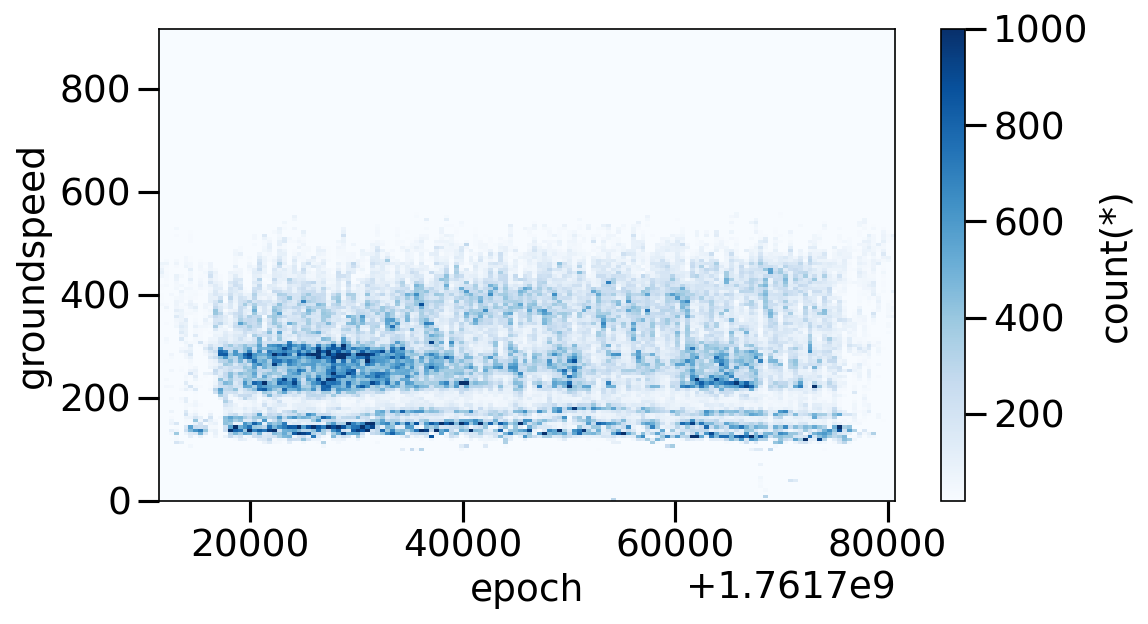

In [7]:
vdf.viz.heatmap(vdf.epoch, vdf.groundspeed,limits=['minmax', 'minmax'],shape=150,colormap='Blues',vmin=20,vmax=1000)

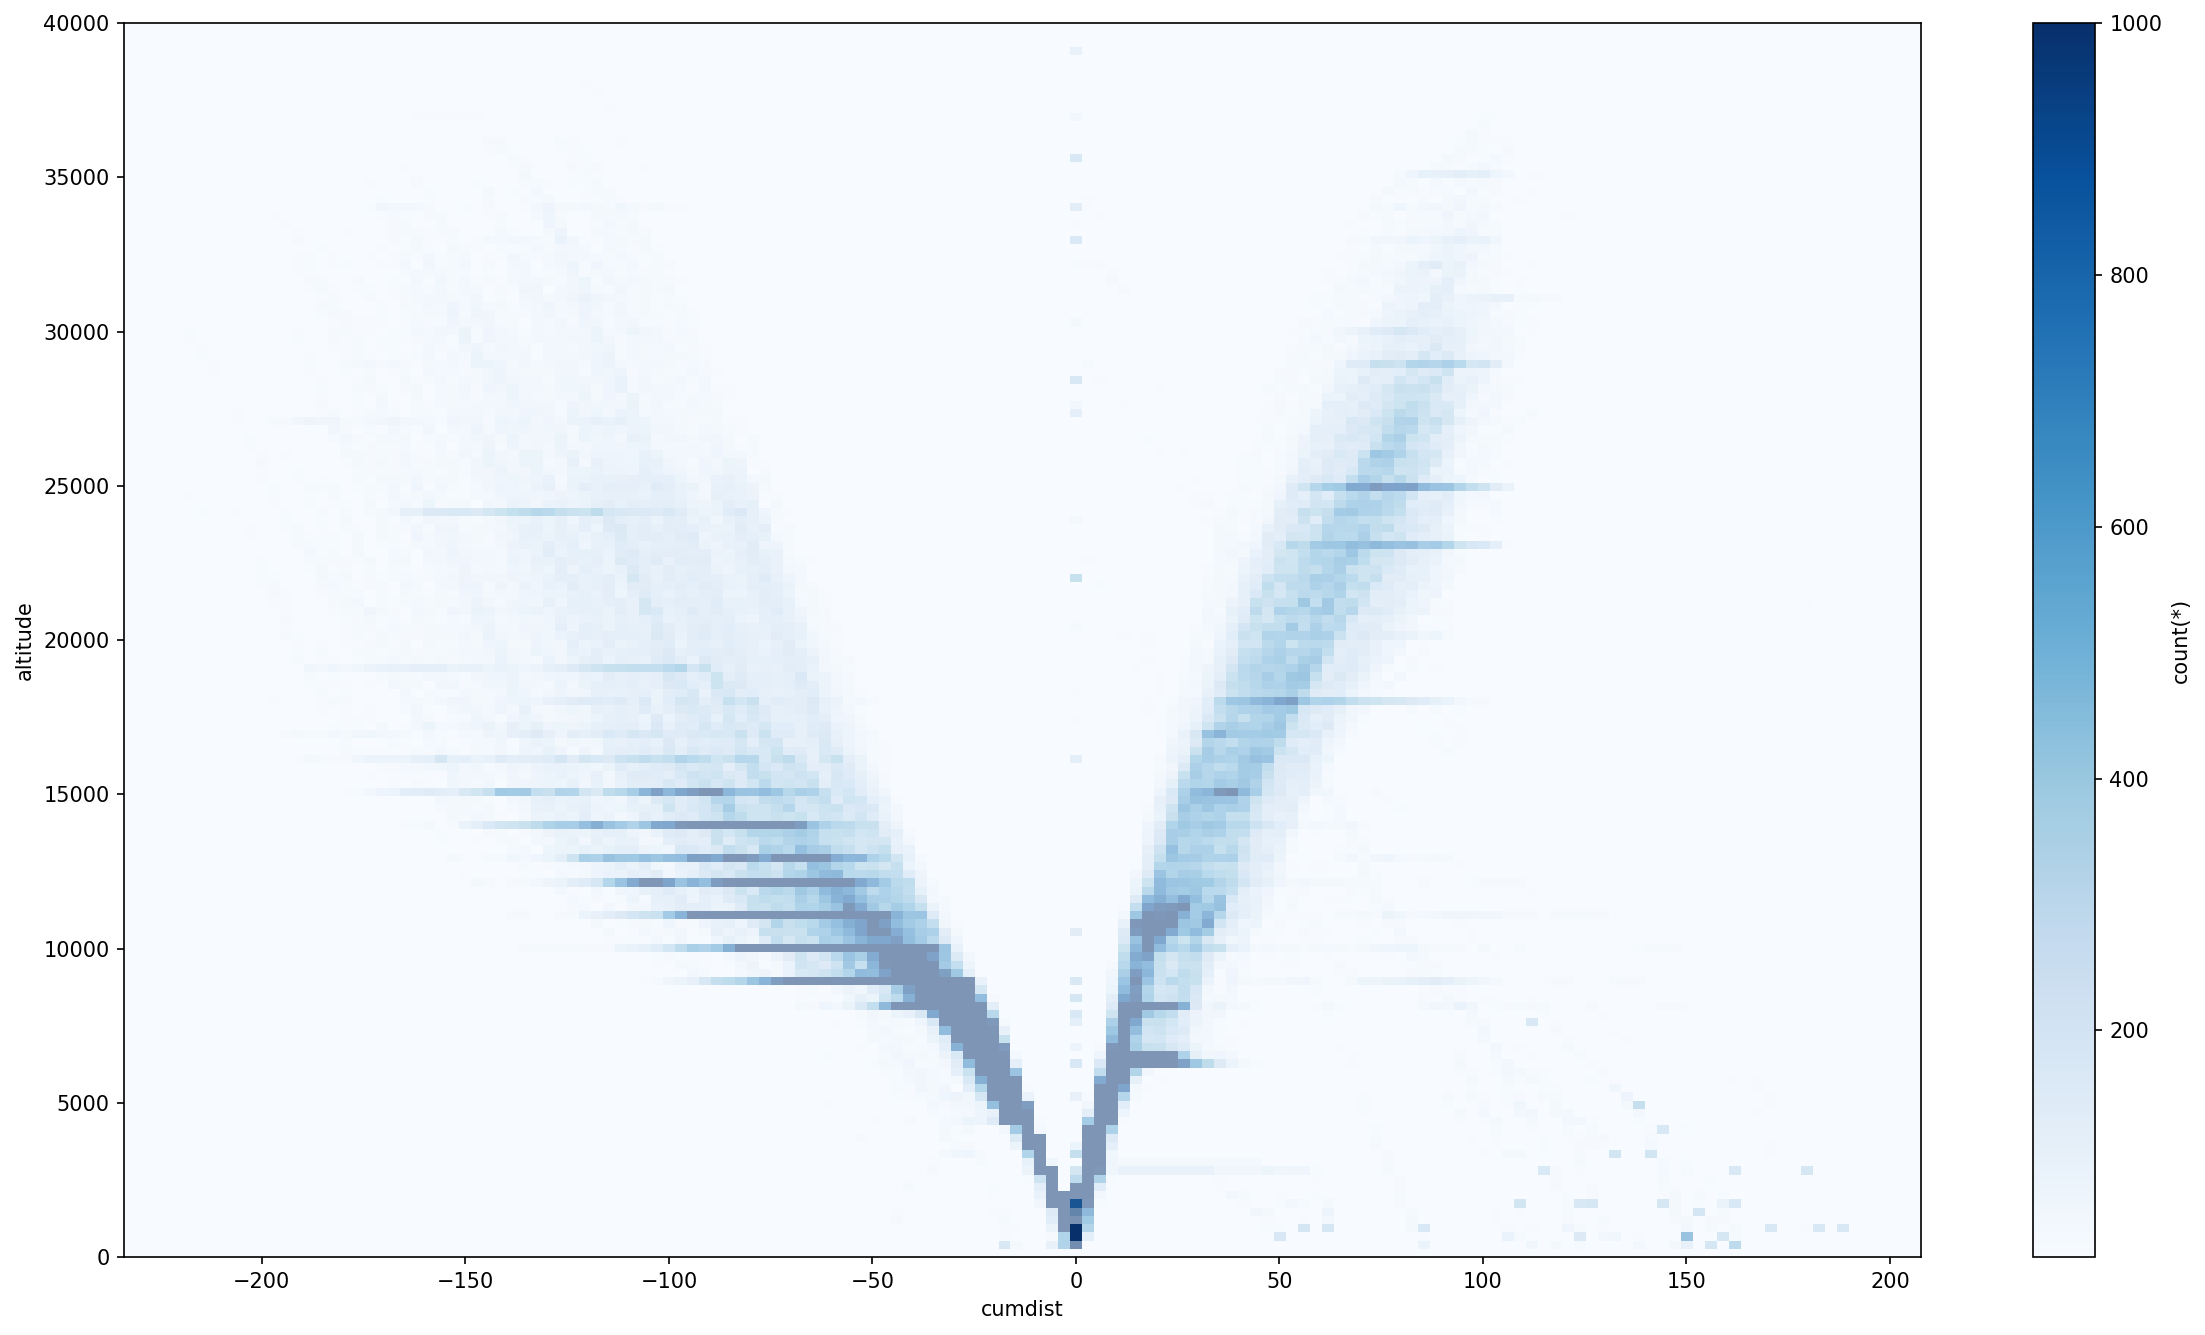

In [9]:
vdf.viz.heatmap(vdf.cumdist, vdf.altitude,limits=['minmax', [0, 40000]],shape=150,selection=[vdf.landing,~vdf.landing],colormap='Blues',vmin=20,vmax=1000)

NameError: name 'vdf' is not defined

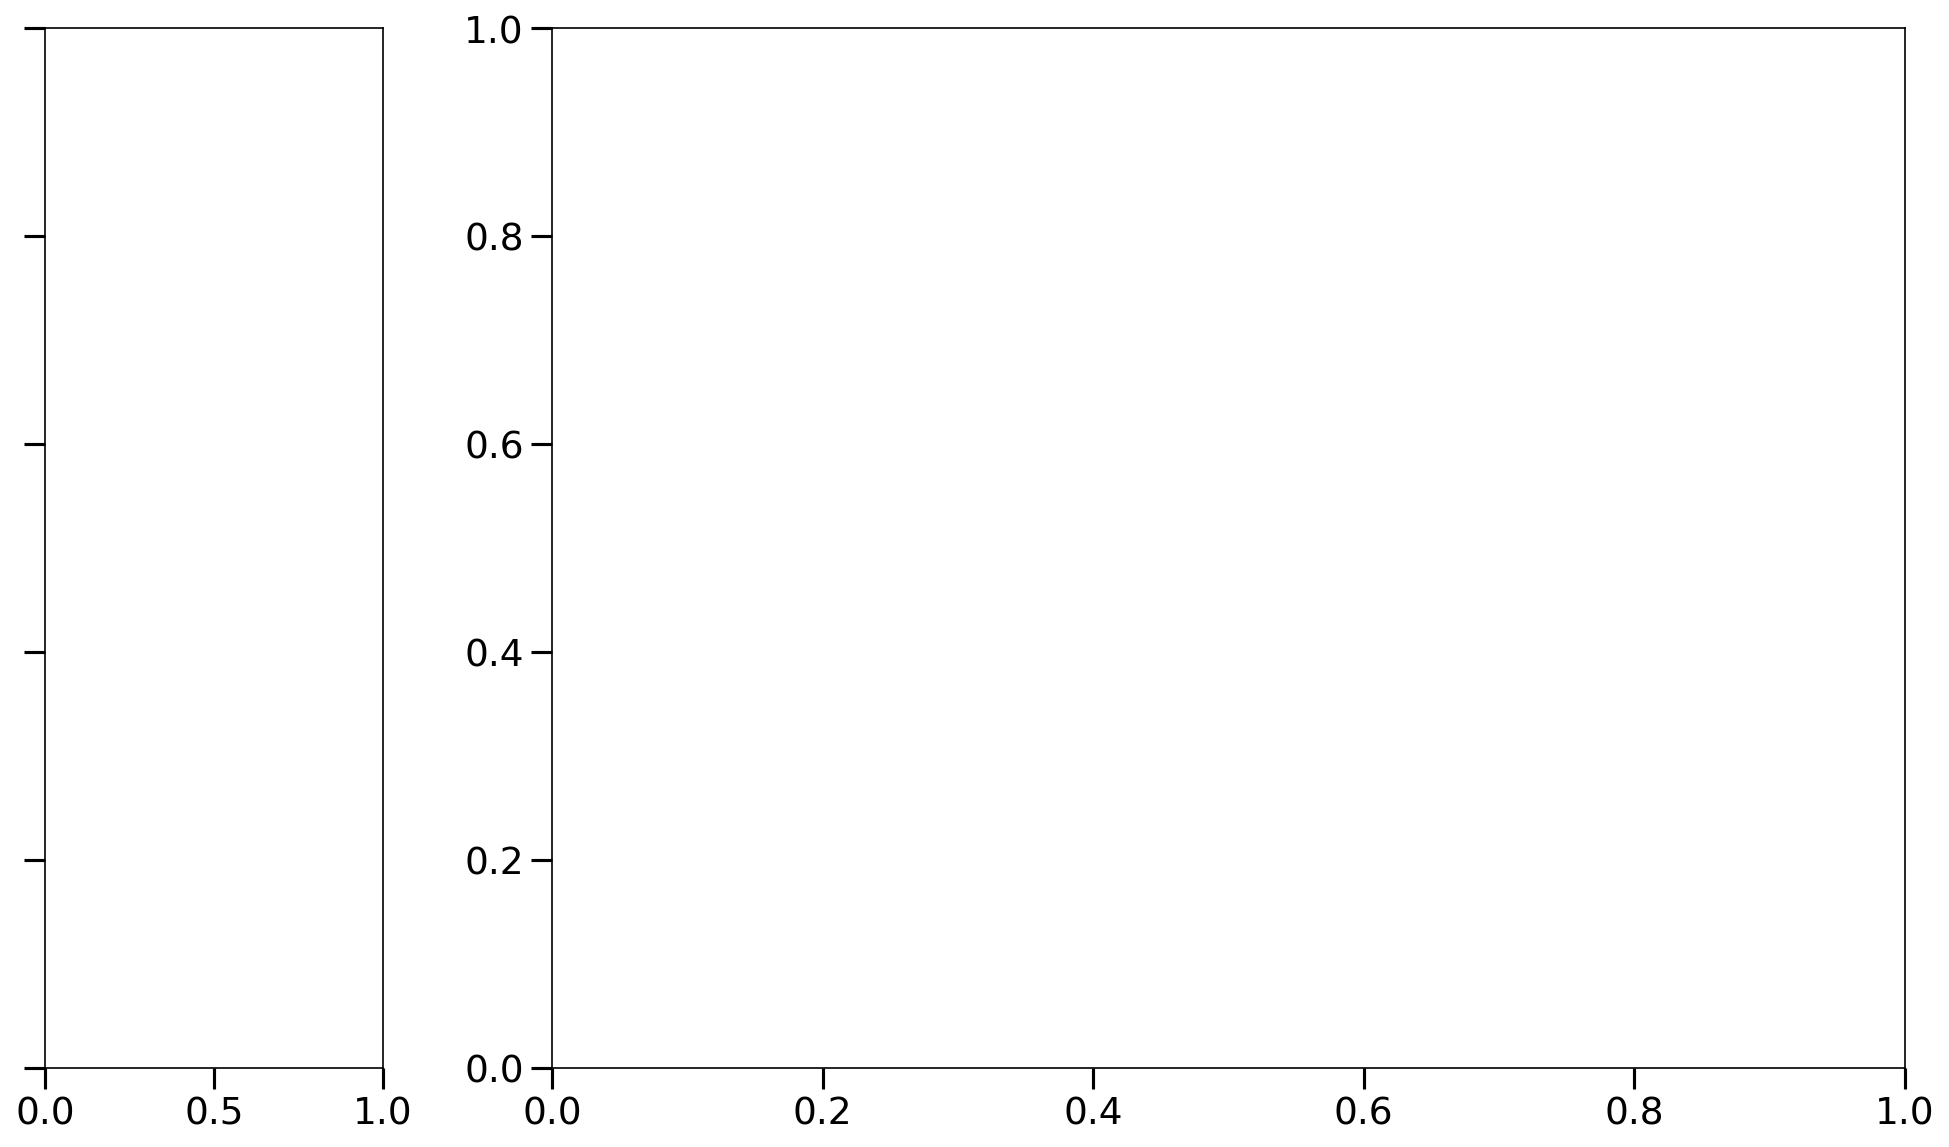

In [ ]:
fig,axs = plt.subplot_mosaic([['hist','heat']],figsize=(16,9),gridspec_kw={'width_ratios':[1,4],'height_ratios':[1]})
axs['hist'].tick_params(axis='y',labelleft=False)
plt.sca(axs['hist'])
#vdf.viz.histogram(vdf.groundspeed)#,selection=[vdf.landing, ~vdf.landing,~vdf.onground])

cumdist_limits = [-200,100]

bins_per_dim = 128
limits = [80,600]
counts = vdf.count(vdf.groundspeed, selection=[vdf.landing,~vdf.landing], binby=vdf.groundspeed, limits=limits, shape=bins_per_dim)
edges = vdf.bin_edges(vdf.groundspeed, limits=limits, shape=bins_per_dim)

print(counts.shape,edges.shape)

centers = (edges[:-1] + edges[1:]) / 2
widths = np.diff(edges)

#axs['hist'].barh(centers, counts, height=widths,histtype='step')
axs['hist'].stairs(counts[0], edges, orientation='horizontal', fill=False,color='blue',label='Landing aircraft')
axs['hist'].stairs(counts[1], edges, orientation='horizontal', fill=False,color='red',label='Departing aircraft')
axs['hist'].invert_xaxis()
axs['hist'].set_xlabel('Datapoints Count')
axs['hist'].set_ylabel('Ground speed (kts)')
axs['hist'].grid(True, axis='x', alpha=0.5)
axs['hist'].legend(loc='upper left')

plt.sca(axs['heat'])
h = vdf.count(binby=['cumdist', 'groundspeed'], selection=[vdf.landing,~vdf.landing], limits=[cumdist_limits, limits], shape=bins_per_dim)
print(h.shape)
h1 = h[0]
h2 = h[1]

h1_masked = np.ma.masked_where(h1 < 20, h1)
h2_masked = np.ma.masked_where(h2 < 20, h2)

# Second heatmap
im2 = axs['heat'].imshow(
    h2_masked.T,
    origin='lower',
    extent=[cumdist_limits[0], cumdist_limits[1], limits[0], limits[1]],
    cmap='Reds',
    vmin=0,vmax=800,
    alpha=1,
    aspect='auto'
)

# First heatmap
im1 = axs['heat'].imshow(
    h1_masked.T,
    origin='lower',
    extent=[cumdist_limits[0], cumdist_limits[1], limits[0], limits[1]],
    cmap='Blues',
    vmin=0,vmax=800,
    alpha=1,
    aspect='auto'
)

cbar1 = fig.colorbar(im1, ax=axs['heat'],pad=-0.02)
cbar1.set_label('Datapoints Count (Landing aircraft)')

cbar2 = fig.colorbar(im2, ax=axs['heat'])
cbar2.set_label('Datapoints Count (Departing aircraft)')

axs['heat'].set_xlabel('Traveled distance to airport (NM)')

fig.tight_layout()


#vdf.viz.heatmap(vdf.cumdist, vdf.groundspeed, normalize=None, selection=[vdf.landing],vmin=0, vmax=150, colormap='Blues',shape=150, colorbar=True,
#                xlabel='Traveled distance (NM)', title='2D histogram of ground speed vs traveled distance')
plt.savefig('groundspeed_vs_cumdist.svg')
plt.show()

(2, 128) (129,)
(2, 128, 128)


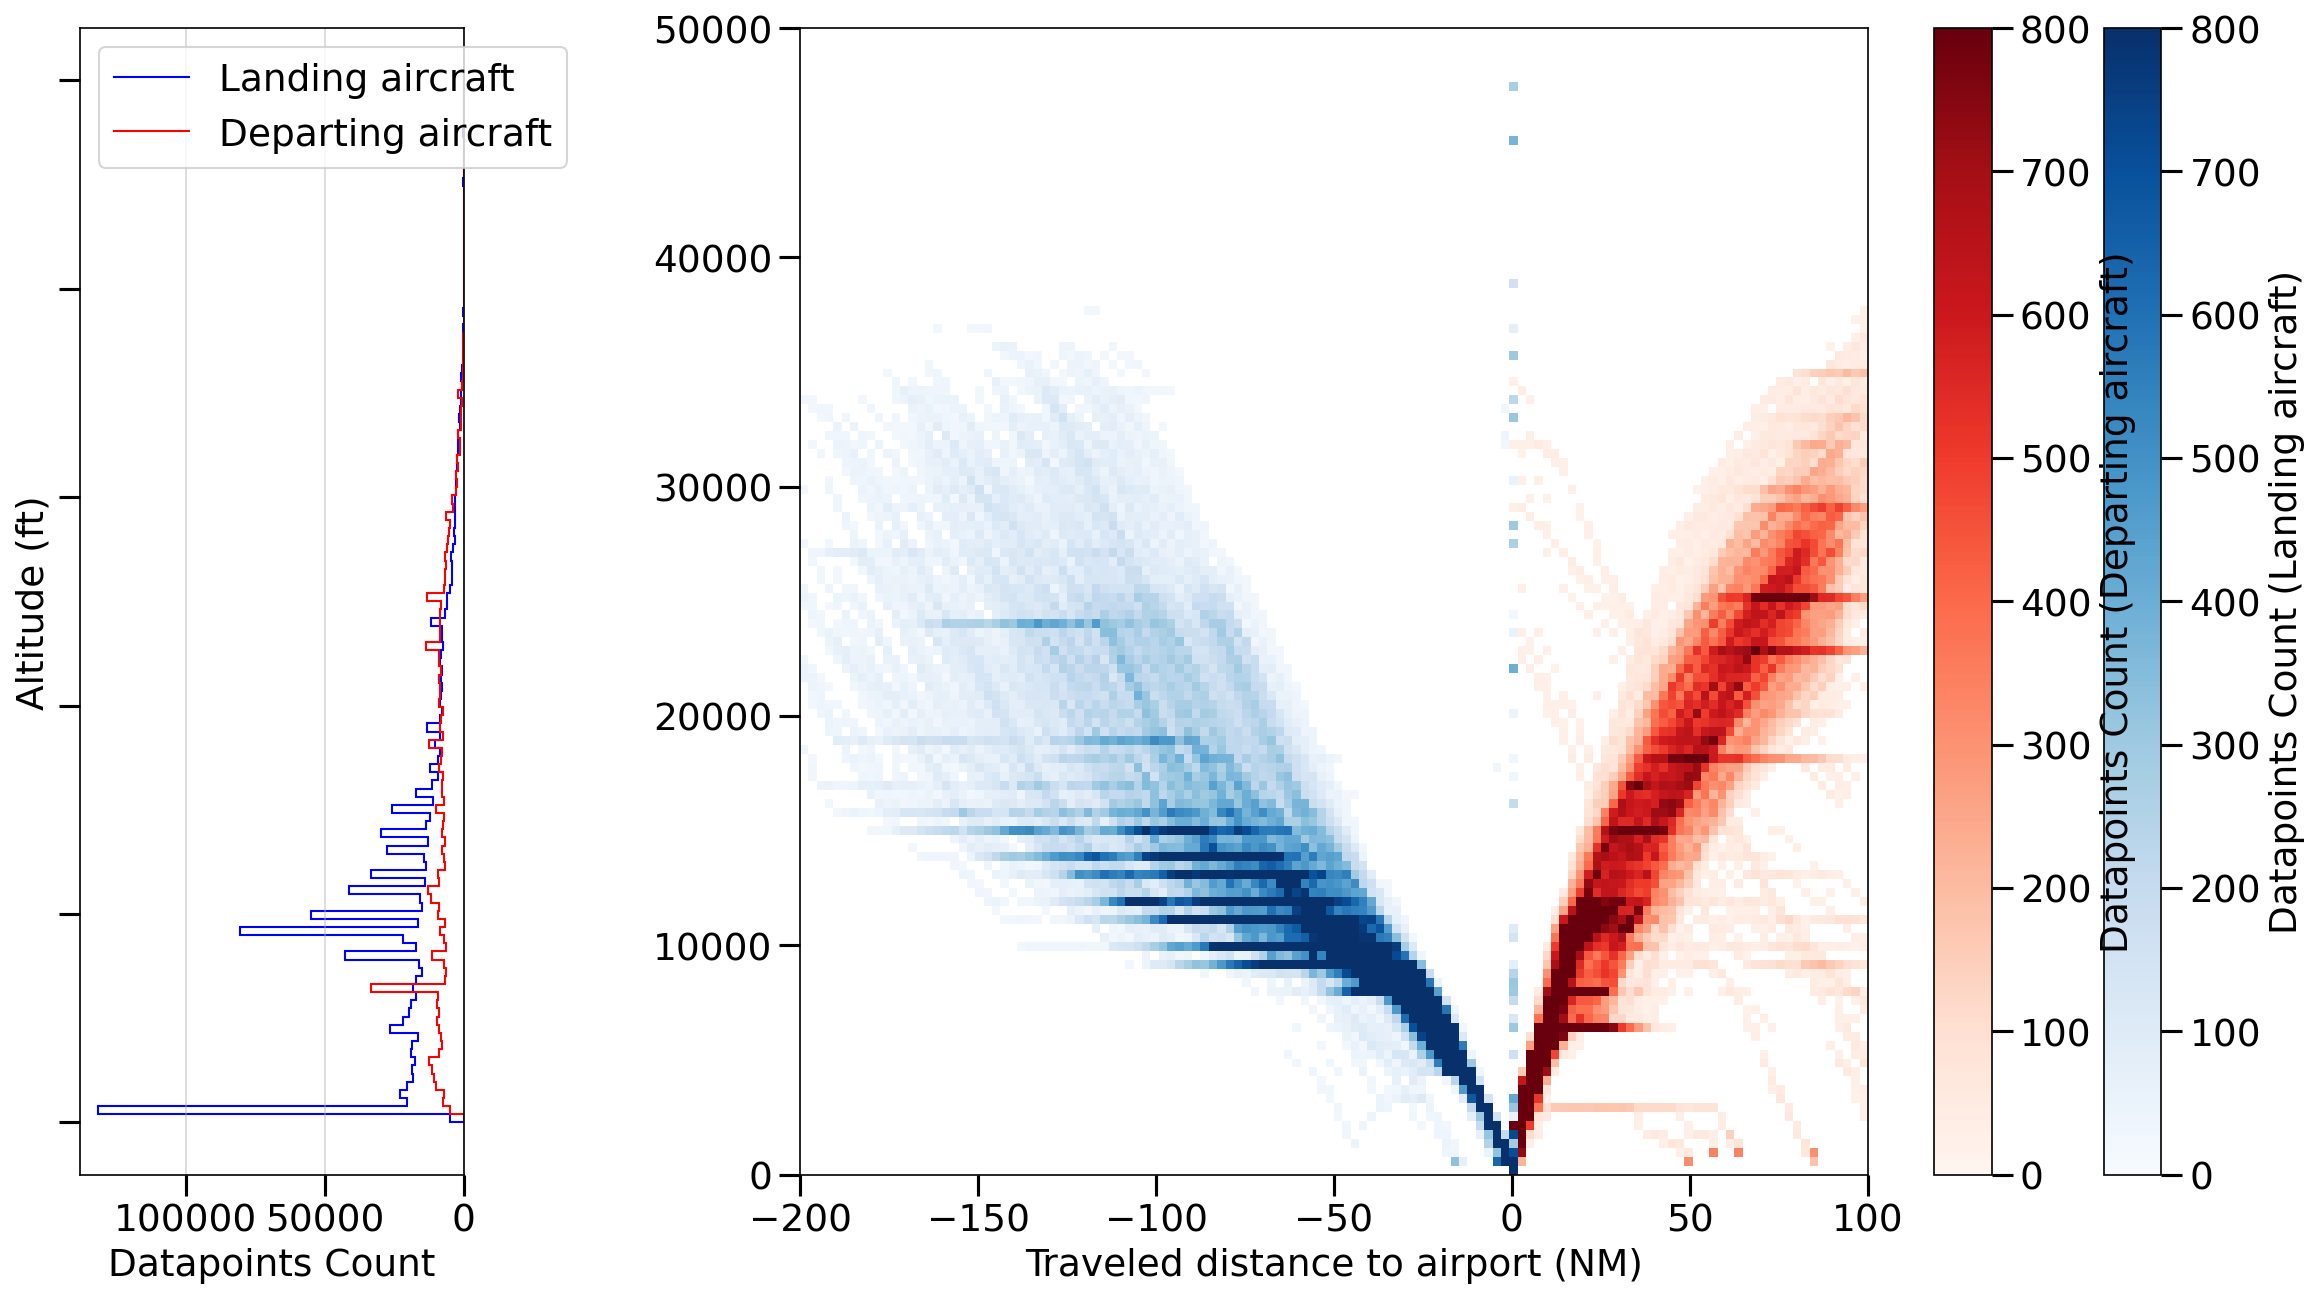

In [18]:
fig,axs = plt.subplot_mosaic([['hist','heat']],figsize=(16,9),gridspec_kw={'width_ratios':[1,4],'height_ratios':[1]})
axs['hist'].tick_params(axis='y',labelleft=False)
plt.sca(axs['hist'])
#vdf.viz.histogram(vdf.altitude)#,selection=[vdf.landing, ~vdf.landing,~vdf.onground])

cumdist_limits = [-200,100]

bins_per_dim = 128
limits = [0,50000]
counts = vdf.count(vdf.altitude, selection=[vdf.landing,~vdf.landing], binby=vdf.altitude, limits=limits, shape=bins_per_dim)
edges = vdf.bin_edges(vdf.altitude, limits=limits, shape=bins_per_dim)

print(counts.shape,edges.shape)

centers = (edges[:-1] + edges[1:]) / 2
widths = np.diff(edges)

#axs['hist'].barh(centers, counts, height=widths,histtype='step')
axs['hist'].stairs(counts[0], edges, orientation='horizontal', fill=False,color='blue',label='Landing aircraft')
axs['hist'].stairs(counts[1], edges, orientation='horizontal', fill=False,color='red',label='Departing aircraft')
axs['hist'].invert_xaxis()
axs['hist'].set_xlabel('Datapoints Count')
axs['hist'].set_ylabel('Altitude (ft)')
axs['hist'].grid(True, axis='x', alpha=0.5)
axs['hist'].legend(loc='upper left')

plt.sca(axs['heat'])
h = vdf.count(binby=['cumdist', 'altitude'], selection=[vdf.landing,~vdf.landing], limits=[cumdist_limits, limits], shape=bins_per_dim)
print(h.shape)
h1 = h[0]
h2 = h[1]

h1_masked = np.ma.masked_where(h1 < 20, h1)
h2_masked = np.ma.masked_where(h2 < 20, h2)

# Second heatmap
im2 = axs['heat'].imshow(
    h2_masked.T,
    origin='lower',
    extent=[cumdist_limits[0], cumdist_limits[1], limits[0], limits[1]],
    cmap='Reds',
    vmin=0,vmax=800,
    alpha=1,
    aspect='auto'
)

# First heatmap
im1 = axs['heat'].imshow(
    h1_masked.T,
    origin='lower',
    extent=[cumdist_limits[0], cumdist_limits[1], limits[0], limits[1]],
    cmap='Blues',
    vmin=0,vmax=800,
    alpha=1,
    aspect='auto'
)

cbar1 = fig.colorbar(im1, ax=axs['heat'],pad=-0.02)
cbar1.set_label('Datapoints Count (Landing aircraft)')

cbar2 = fig.colorbar(im2, ax=axs['heat'])
cbar2.set_label('Datapoints Count (Departing aircraft)')

axs['heat'].set_xlabel('Traveled distance to airport (NM)')

fig.tight_layout()


#vdf.viz.heatmap(vdf.cumdist, vdf.altitude, normalize=None, selection=[vdf.landing],vmin=0, vmax=150, colormap='Blues',shape=150, colorbar=True,
#                xlabel='Traveled distance (NM)', title='2D histogram of ground speed vs traveled distance')
plt.savefig('altitude_vs_cumdist.svg')
plt.show()

In [4]:
resampled = tr.resample('1min').eval(8)

In [7]:
from itertools import combinations

def closest_aircraft(df):
    results = []

    for timestamp, group in df.groupby("timestamp"):
        if len(group) < 2:
            continue

        # Evaluate every unique pair of aircraft
        pairs = (
            (
                distance(
                    a.latitude, a.longitude,
                    b.latitude, b.longitude,
                ),
                a.flight_id,
                b.flight_id,
            )
            for a, b in combinations(group.itertuples(index=False), 2)
        )

        min_distance, flight_id_1, flight_id_2 = min(pairs)

        results.append({
            "timestamp": timestamp,
            "flight_id_1": flight_id_1,
            "flight_id_2": flight_id_2,
            "distance": min_distance,
        })

    return pd.DataFrame(results)

closest_df = tr.data.dropna(subset=['flight_id','latitude','longitude','altitude'])
closest_df = closest_aircraft(closest_df.where(closest_df['altitude'].between(5000,10000)))


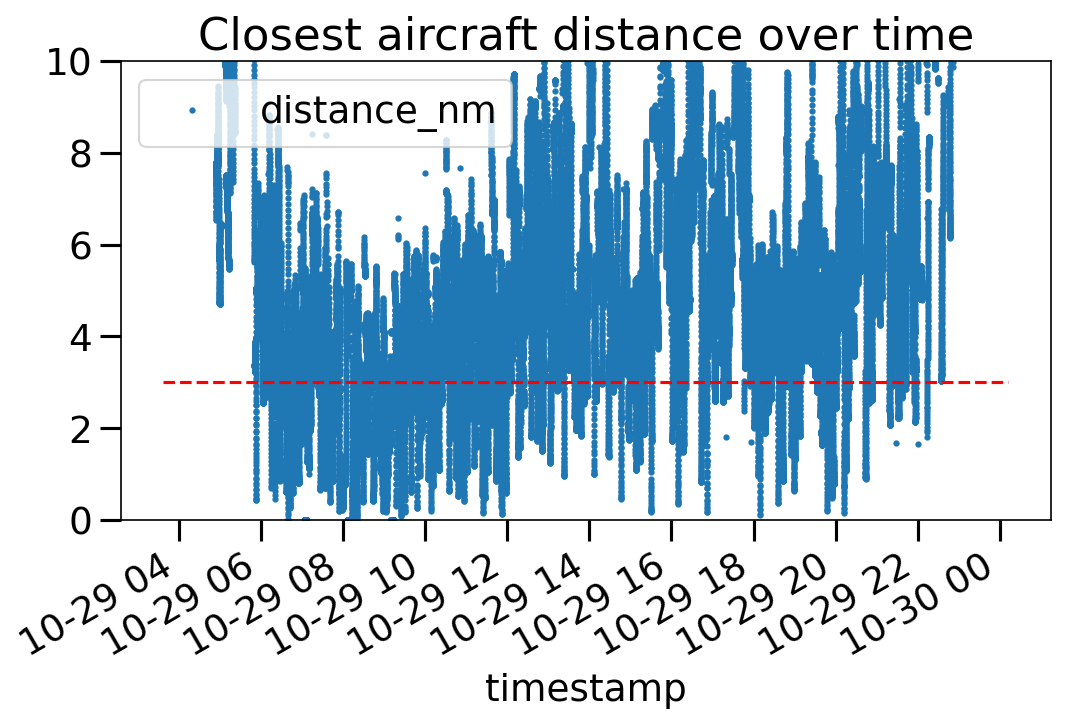

In [8]:
closest_df['distance_nm'] = closest_df['distance'] / NM_TO_METERS
ax = closest_df.plot(x='timestamp', y='distance_nm', kind='line', title='Closest aircraft distance over time',linestyle='',marker='o', markersize=2,)
ax.set_ylim(0, 10)
xlims = ax.get_xlim()
ax.hlines(y=3,xmin=xlims[0], xmax=xlims[1], color='r', linestyle='--', label='3 NM Threshold')
plt.show()